# Test outputs

This notebook checks that preprocessed (raw and interim) NetCDF files exist and can be opened with xarray.

In [11]:
RAW="/home/khizer/scientific_contributions/tutorial-repo/data/raw/METREF/2010/01/NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000.nc"
INTERIM="/home/khizer/scientific_contributions/tutorial-repo/data/interim/2010/01/NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000_processed.nc"

In [12]:
import xarray as xr
import numpy as np

for path in [RAW, INTERIM]:
    print(f"\n{path}")
    with xr.open_dataset(path, decode_cf=True, mask_and_scale=True) as ds:
        print(ds.sizes)
        for name, da in ds.data_vars.items():
            if da.dtype.kind in "iuf":
                valid = int(np.isfinite(da).sum().compute())
                print(name, "valid:", valid, "/", da.size)
                if valid:
                    print("min/max:", float(da.min().compute()), float(da.max().compute()))


/home/khizer/scientific_contributions/tutorial-repo/data/raw/METREF/2010/01/NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000.nc
Frozen({'time': 1, 'lat': 3201, 'lon': 3201})
METREF valid: 2684646 / 10246401
min/max: 0.0 6.96
quality_flag valid: 8042227 / 10246401
min/max: -4.0 6.0

/home/khizer/scientific_contributions/tutorial-repo/data/interim/2010/01/NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000_processed.nc
Frozen({'time': 1, 'lat': 552, 'lon': 576})
METREF valid: 14073 / 317952
min/max: 2.8766379356384277 3.800269842147827
quality_flag valid: 15622 / 317952
min/max: 0.0 1.0


In [13]:
ds

<xarray.Dataset> Size: 4MB
Dimensions:       (time: 1, lat: 552, lon: 576)
Coordinates:
  * time          (time) datetime64[ns] 8B 2010-01-01
  * lat           (lat) float64 4kB -10.94 -10.89 -10.84 ... 16.51 16.56 16.61
  * lon           (lon) float64 5kB -17.18 -17.13 -17.08 ... 11.47 11.52 11.57
Data variables:
    METREF        (time, lat, lon) float32 1MB nan nan nan nan ... nan nan nan
    quality_flag  (time, lat, lon) float64 3MB nan nan nan nan ... nan nan nan
Attributes: (12/29)
    CDI:                        Climate Data Interface version 2.4.0 (https:/...
    Conventions:                CF-1.6
    institution:                IM-PT
    date_created:               2020-11-09T17:30:27Z
    algorithm_version:          1.3.2
    base_algorithm_version:     1.0.3
    ...                         ...
    westernmost_longitude:      80.0
    spatial_resolution:          0.05x 0.05
    geospatial_lat_units:       degrees_north
    geospatial_lon_units:       degrees_east
    netcdf_version_id:          netCDF4
    CDO:                        Climate Data Operators version 2.4.0 (https:/...

In [1]:
from pathlib import Path
import xarray as xr

# Paths
repo_root = next(
    parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (parent / "pyproject.toml").exists()
)
raw = repo_root / "data" / "raw" / "METREF"
interim = repo_root / "data" / "interim"
# Check that the directories exist.
if not raw.exists():
    raise FileNotFoundError(f"Raw data directory {raw} does not exist.")
if not interim.exists():
    raise FileNotFoundError(f"Interim data directory {interim} does not exist.")
rawfiles = sorted(raw.rglob("*.nc"))
interimfiles = sorted(interim.rglob("*.nc"))
len(rawfiles), len(interimfiles)

(30, 30)

In [6]:
from pathlib import Path
import sys

repo_root = next(
    parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (parent / "pyproject.toml").exists()
)
module_dir = repo_root / "code" / "plot_utils"

print("Notebook folder:", repo_root)
print("Module folder exists:", module_dir.exists())
print("Module file exists:", (module_dir / "adaptive_cube_plot.py").exists())

Notebook folder: /home/khizer/scientific_contributions/tutorial-repo
Module folder exists: True
Module file exists: True


In [7]:
sys.path.insert(0, str(module_dir))

from adaptive_cube_plot import plot_time_slices, plot_spatial_timeseries

In [6]:
ds = xr.open_mfdataset(interimfiles, combine="by_coords", parallel=True)
ds

<xarray.Dataset> Size: 114MB
Dimensions:       (time: 30, lat: 552, lon: 576)
Coordinates:
  * time          (time) datetime64[ns] 240B 2020-06-01 ... 2020-06-30
  * lat           (lat) float64 4kB -10.94 -10.89 -10.84 ... 16.51 16.56 16.61
  * lon           (lon) float64 5kB -17.18 -17.13 -17.08 ... 11.47 11.52 11.57
Data variables:
    METREF        (time, lat, lon) float32 38MB dask.array<chunksize=(1, 552, 576), meta=np.ndarray>
    quality_flag  (time, lat, lon) float64 76MB dask.array<chunksize=(1, 552, 576), meta=np.ndarray>
Attributes: (12/29)
    CDI:                        Climate Data Interface version 2.4.0 (https:/...
    Conventions:                CF-1.6
    institution:                IM-PT
    date_created:               2020-10-23T07:20:57Z
    algorithm_version:          1.3.2
    base_algorithm_version:     1.0.3
    ...                         ...
    westernmost_longitude:      80.0
    spatial_resolution:          0.05x 0.05
    geospatial_lat_units:       degrees_north
    geospatial_lon_units:       degrees_east
    netcdf_version_id:          netCDF4
    CDO:                        Climate Data Operators version 2.4.0 (https:/...

In [8]:
ds.METREF.values

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(1, 3201, 3201))

In [3]:
ds_raw = xr.open_mfdataset(rawfiles, combine="by_coords", parallel=True)
ds_raw

C:\Users\b1113715\AppData\Local\Temp\ipykernel_35148\335045880.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_raw = xr.open_mfdataset(rawfiles, combine="by_coords", parallel=True)


<xarray.Dataset> Size: 5GB
Dimensions:       (time: 30, lat: 3201, lon: 3201)
Coordinates:
  * time          (time) datetime64[ns] 240B 2020-06-01 ... 2020-06-30
  * lat           (lat) float32 13kB 80.0 79.95 79.9 ... -79.9 -79.95 -80.0
  * lon           (lon) float32 13kB -80.0 -79.95 -79.9 ... 79.9 79.95 80.0
Data variables:
    METREF        (time, lat, lon) float64 2GB dask.array<chunksize=(1, 100, 100), meta=np.ndarray>
    crs           (time) |S1 30B b'' b'' b'' b'' b'' b'' ... b'' b'' b'' b'' b''
    quality_flag  (time, lat, lon) float64 2GB dask.array<chunksize=(1, 100, 100), meta=np.ndarray>
Attributes: (12/27)
    date_created:               2020-10-23T07:20:57Z
    algorithm_version:          1.3.2
    base_algorithm_version:     1.0.3
    processing_level:           03
    platform:                   MSG4
    sensor:                     SEVI
    ...                         ...
    westernmost_longitude:      80.0
    spatial_resolution:          0.05x 0.05
    geospatial_lat_units:       degrees_north
    geospatial_lon_units:       degrees_east
    Conventions:                CF-1.6
    netcdf_version_id:          netCDF4

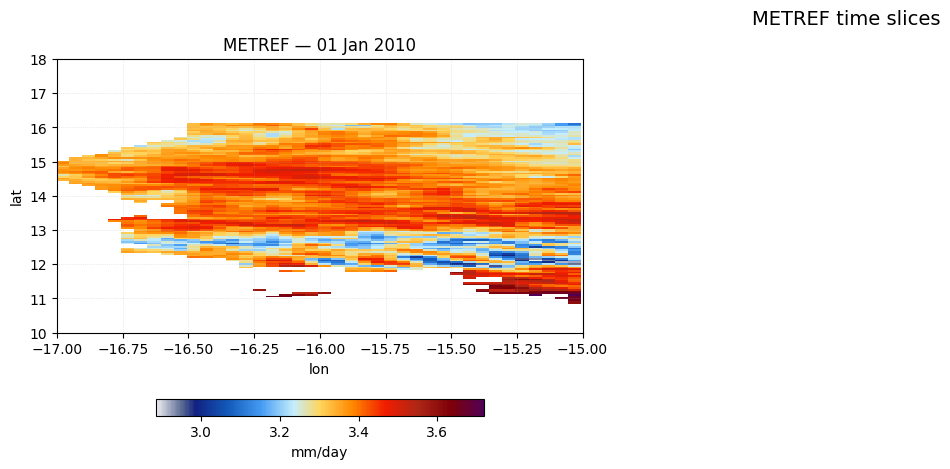

In [29]:
fig, axes = plot_time_slices(
    ds,
    var="METREF",
    time_index=[0],
    ncols=3,
    extent=[-17, -15, 10, 18],

)